#### Forward dynamics of `ROBOTIS FFW SG2`
- `sg2`: `s`werve drive with `g`ripper and `2`fingers

In [1]:
from package.init_scripts.init_ipython_setup import *
from package.init_scripts.init_qt import *
from package.mujoco_sim import *
from package.kinematics import *
from package.utility import *
from package.qt import *
from PyQt5.QtWidgets import QApplication
app = QApplication(sys.argv)

[qt] package initialized.
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files=[
        "../asset/floor/floor_simple_white.xml",
        "../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml",
        "../asset/object/table_0.xml",
        "../asset/objaverse/can/can_0/model_new_unscaled.xml",
        "../asset/objaverse/can/can_2/model_new_unscaled.xml",
    ],
    output_xml_path = 'xml/scene_ffw_sg2.xml',
)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)

[merge_mjcfs] Merging [5] MJCF files:
  - [0] [../asset/floor/floor_simple_white.xml]
  - [1] [../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml]
  - [2] [../asset/object/table_0.xml]
  - [3] [../asset/objaverse/can/can_0/model_new_unscaled.xml]
  - [4] [../asset/objaverse/can/can_2/model_new_unscaled.xml]
[merge_mjcfs] Saved merged XML to:[xml/scene_ffw_sg2.xml]
MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


In [3]:
# Group ctrls
ctrl_group = group_by_prefix(
    items = env.ctrl_names,
    prefix_dict = {
        "wheel": ["left_wheel","right_wheel","rear_wheel"],
        "lift": "lift",
        "head": "head",
        "arm": ["arm_l","arm_r"],
        "gripper": ["gripper_l_joint1","gripper_r_joint1"],
    },
    verbose = False,
)
ctrl_slider_items = [
    ("wheel","Wheel ctrl"),
    ("lift", "Lift ctrl"),
    ("head", "Head ctrl"),
    ("arm",  "Arm ctrl"),
    ("gripper", "Gripper ctrl"),
]
print("[ctrl_names]:[%d]"%(len(env.ctrl_names)))


[ctrl_names]:[25]


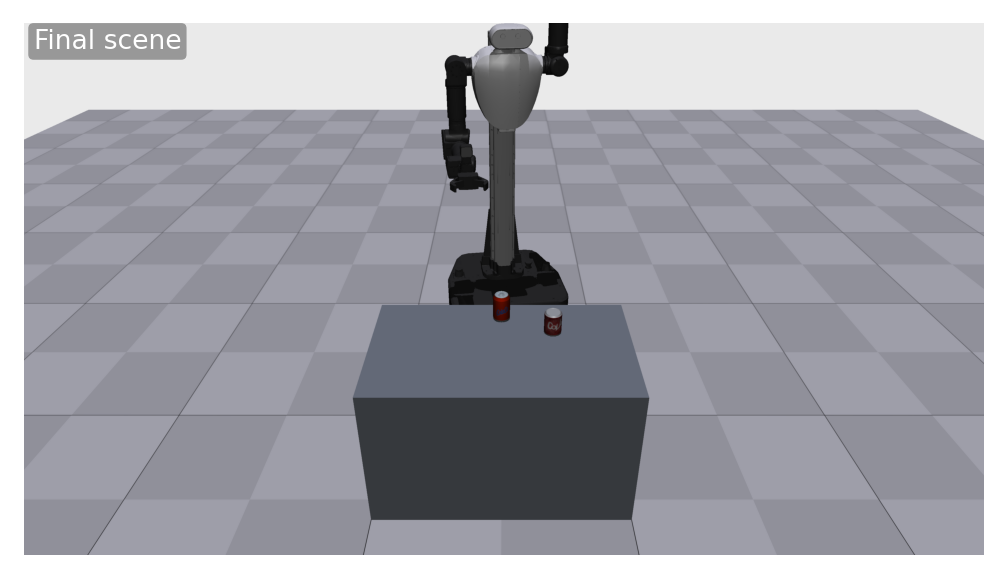

Done.


In [4]:
# Reset environment
env.reset()
env.init_viewer(title="FFW SG2", width=1.0, height=1.0, fontscale=200)
env.viewer.set_cam_info(180, 3.2, -30, [0.02, 0.01, 0.4])
env.viewer.set_transparency(transparent=False)
env.viewer.set_geomgroup(group_2=True,group_3=False)
env.viewer.set_sitegroup(group_0=False)

# Place objects
env.set_p("body_object_table_0","body",(0.8,0.0,0.0))
env.set_p("body_obj_can_0","base",(0.60,0.00,0.70))
env.set_p("body_obj_can_2","base",(0.70,0.20,0.70))
env.forward(q=[-90*D2R,-90*D2R],joint_names=["arm_l_joint4","arm_r_joint4"])
env.set_zero_qvel()

# Ctrl slider
ctrl_vals = env.get_ctrl_qpos(ctrl_names=env.ctrl_names)
env.data.ctrl[:] = ctrl_vals.copy()
ctrl_mins = np.asarray(env.ctrl_mins, dtype=np.float64).copy()
ctrl_maxs = np.asarray(env.ctrl_maxs, dtype=np.float64).copy()
bad_range = (~np.isfinite(ctrl_mins)) | (~np.isfinite(ctrl_maxs)) | (ctrl_maxs <= ctrl_mins)
ctrl_mins[bad_range] = ctrl_vals[bad_range] - 1.0
ctrl_maxs[bad_range] = ctrl_vals[bad_range] + 1.0
ctrl_vals = np.clip(ctrl_vals, ctrl_mins, ctrl_maxs)
env.data.ctrl[:] = ctrl_vals.copy()
slider_ctrl = MultiSliderQtWidget(
    title         = "Ctrl sliders (%d)" % len(env.ctrl_names),
    label_texts   = env.ctrl_names,
    slider_mins   = ctrl_mins,
    slider_maxs   = ctrl_maxs,
    slider_vals   = ctrl_vals,
    slider_steps  = 10000,
    x_offset      = 0.00, y_offset = 0.05,
    window_width  = 0.30, window_height = 0.80,
    fontsize      = 30,
)

# Qpos tracking slider
qpos_vals = env.get_qpos(joint_names=env.rev_pri_joint_names)
qpos_mins = np.asarray(env.rev_pri_joint_mins, dtype=np.float64).copy()
qpos_maxs = np.asarray(env.rev_pri_joint_maxs, dtype=np.float64).copy()
bad_qpos_range = (~np.isfinite(qpos_mins)) | (~np.isfinite(qpos_maxs)) | (qpos_maxs <= qpos_mins)
qpos_mins[bad_qpos_range] = qpos_vals[bad_qpos_range] - 1.0
qpos_maxs[bad_qpos_range] = qpos_vals[bad_qpos_range] + 1.0
sliders_qpos = MultiSliderQtWidget(
    title         = "Qpos monitor (%d)" % len(env.rev_pri_joint_names),
    label_texts   = env.rev_pri_joint_names,
    slider_mins   = qpos_mins,
    slider_maxs   = qpos_maxs,
    slider_vals   = np.clip(qpos_vals, qpos_mins, qpos_maxs),
    slider_steps  = 10000,
    x_offset      = 0.70, y_offset = 0.05,
    window_width  = 0.30, window_height = 0.80,
    fontsize      = 30,
)


# Gravity compensation button
buttons = MultiRadioQtWidget(
    title         = "Gravity compensation",
    label_texts   = ["Gravity compensation"],
    option_texts  = [["On","Off"]],
    initial_texts = ["On"],
    x_offset      = 0.80, y_offset = 0.90,
    window_width  = 0.20, window_height = 0.10,
    fontsize      = 30,
)

# Timers
sim_nstep = 30
tmr_sim = SimpleTimer(name="Sim",Hz=1.0/(env.dt*sim_nstep),verbose=True)
tmr_render = SimpleTimer(name="Render",Hz=50,verbose=True)

# Loop
q_err_sorted = np.zeros(3)
ctrl_sorted = [env.ctrl_names[0]]*3
tmr_sim.start(); tmr_render.start(); env.reset_wall_time()
while env.is_viewer_alive():
    app.processEvents()
    # Update
    if tmr_sim.do_run():
        ctrl_vals[:] = slider_ctrl.get_values()
        on_flag = buttons.get_button_option("Gravity compensation") == "On"
        env.compensate_gravity(root_body_names=["base_link"],on=on_flag)
        env.step(ctrl=ctrl_vals,nstep=sim_nstep)
        sliders_qpos.set_values(env.get_qpos(joint_names=env.rev_pri_joint_names))
        T_can0 = env.get_T("body_obj_can_0","body")
        T_can2 = env.get_T("body_obj_can_2","body")
        q_err = np.asarray(ctrl_vals,dtype=np.float64) - env.get_ctrl_qpos(ctrl_names=env.ctrl_names)
        idx_sort = np.argsort(-np.abs(q_err))
        q_err_sorted = q_err[idx_sort]
        ctrl_sorted = [env.ctrl_names[i] for i in idx_sort]
        tmr_sim.end()

    # Render
    if tmr_render.do_run():
        env.plot_time(plot_loop_freq=False)
        for topk in range(3):
            env.viewer_text_overlay("Top [%d] tracking error"%(topk),"--------------")
            env.viewer_text_overlay(" Contrl name","[%s]"%(ctrl_sorted[topk]))
            env.viewer_text_overlay(" Tracking error","[%.3f]"%(q_err_sorted[topk]))
        env.plot_global_coordinate_axes()
        env.plot_contact_info(plot_contact=True,rate=0.5)
        env.plot_links_between_bodies(r=0.001)
        env.plot_rev_joint_axis(rate=0.5)
        env.plot_T(T=T_can0,axis_len=0.05)
        env.plot_T(T=T_can2,axis_len=0.05)
        env.render()
        tmr_render.end()

# Close
imshow(env.final_rgb_img,fig_w=4,title="Final scene",title_fs=8)
env.close_viewer()
slider_ctrl.close()
buttons.close()
sliders_qpos.close()
print_green("Done.")
